In [2]:
# ============================================================
# FINAL REPORT - CELL 1: Setup and Load Everything Needed
# ============================================================

import numpy as np
import pandas as pd
import os
import joblib
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = "C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR  = os.path.join(PROJECT_ROOT, "results")
MODELS_DIR   = os.path.join(PROJECT_ROOT, "models")
PLOTS_DIR    = os.path.join(PROJECT_ROOT, "plots")
SEQ_DIR      = os.path.join(RESULTS_DIR, "sequences")

CITIES = ['kano', 'maid', 'abuja']
CITY_LABELS = {'kano': 'Kano', 'maid': 'Maiduguri', 'abuja': 'Abuja'}

# ── Reload test data + scalers ──
data = {}
for city in CITIES:
    data[city] = {
        'X_test': np.load(os.path.join(SEQ_DIR, f'X_test_{city}.npy')),
        'y_test': np.load(os.path.join(SEQ_DIR, f'y_test_{city}.npy')),
        'tgt_scaler': joblib.load(os.path.join(MODELS_DIR, f'tgt_scaler_{city}.pkl')),
    }

# ── Same evaluation function used throughout the project ──
def evaluate_model(y_pred_norm, y_test_norm, tgt_scaler):
    y_pred_kw = tgt_scaler.inverse_transform(y_pred_norm.reshape(-1, 1)).flatten()
    y_true_kw = tgt_scaler.inverse_transform(y_test_norm.reshape(-1, 1)).flatten()
    mask = y_true_kw > 0
    y_true_day, y_pred_day = y_true_kw[mask], y_pred_kw[mask]
    rmse = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    mae  = mean_absolute_error(y_true_day, y_pred_day)
    mape = np.mean(np.abs((y_true_day - y_pred_day) / (y_true_day + 1e-8))) * 100
    r2   = r2_score(y_true_day, y_pred_day)
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R2': r2}

results = {city: {} for city in CITIES}

# ── Load the multi-run averaged baseline results (already saved to CSV) ──
multi_run_df = pd.read_csv(os.path.join(RESULTS_DIR, 'multi_run_validated_comparison.csv'))

# ── Evaluate CNN-biLSTM (base model) ──
for city in CITIES:
    cnn_bilstm_model = load_model(os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras'))
    y_pred = cnn_bilstm_model.predict(data[city]['X_test'], verbose=0).flatten()
    results[city]['cnn_bilstm'] = evaluate_model(y_pred, data[city]['y_test'], data[city]['tgt_scaler'])

# ── Evaluate Standalone XGBoost (original settings) ──
for city in CITIES:
    xgb_only_model = joblib.load(os.path.join(MODELS_DIR, f'xgb_only_{city}.pkl'))
    X_test_flat = data[city]['X_test'][:, -1, :]
    y_pred = xgb_only_model.predict(X_test_flat)
    results[city]['xgb_only'] = evaluate_model(y_pred, data[city]['y_test'], data[city]['tgt_scaler'])

print("✅ Setup complete — CNN-biLSTM and Standalone XGBoost evaluated")

✅ Setup complete — CNN-biLSTM and Standalone XGBoost evaluated


In [3]:
# ============================================================
# FINAL REPORT - CELL 2: Rebuild v3 Features, Evaluate Hybrid v3 (Optuna)
# ============================================================

FEATURE_NAMES_17 = [
    'GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed',
    'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos',
    'DayOfYear_sin', 'DayOfYear_cos', 'Season_encoded', 'Is_Daytime',
    'PV_Power_Lag1', 'PV_Power_Lag24', 'GHI_Lag1'
]
FEATURE_INDEX = {name: i for i, name in enumerate(FEATURE_NAMES_17)}
GHI_IDX, HUMIDITY_IDX, CLEARNESS_IDX = FEATURE_INDEX['GHI'], FEATURE_INDEX['Humidity'], FEATURE_INDEX['Clearness']

def build_v3_features(X_sequences, cnn_pred_norm):
    last_timestep = X_sequences[:, -1, :]
    cnn_pred_col = cnn_pred_norm.reshape(-1, 1)

    rolling_features = []
    for window in [3, 6]:
        recent_window = X_sequences[:, -window:, :]
        for feat_idx in [GHI_IDX, HUMIDITY_IDX, CLEARNESS_IDX]:
            rolling_features.append(recent_window[:, :, feat_idx].mean(axis=1))
            rolling_features.append(recent_window[:, :, feat_idx].std(axis=1))
    rolling_matrix = np.column_stack(rolling_features)

    season, clearness = last_timestep[:, FEATURE_INDEX['Season_encoded']], last_timestep[:, CLEARNESS_IDX]
    month_cos, doy_cos = last_timestep[:, FEATURE_INDEX['Month_cos']], last_timestep[:, FEATURE_INDEX['DayOfYear_cos']]
    humidity, ghi = last_timestep[:, HUMIDITY_IDX], last_timestep[:, GHI_IDX]

    interactions = np.column_stack([season*clearness, doy_cos*humidity, month_cos*ghi, season*humidity])
    return np.hstack([last_timestep, cnn_pred_col, rolling_matrix, interactions])

# ── Build 34-feature test set and evaluate the Optuna-tuned corrector ──
for city in CITIES:
    cnn_bilstm_model = load_model(os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras'))
    cnn_pred_test = cnn_bilstm_model.predict(data[city]['X_test'], verbose=0).flatten()

    X_test_v3 = build_v3_features(data[city]['X_test'], cnn_pred_test)

    xgb_optuna_model = joblib.load(os.path.join(MODELS_DIR, f'xgb_{city}_v3_optuna.pkl'))
    residual_pred = xgb_optuna_model.predict(X_test_v3)
    hybrid_v3_optuna_pred = cnn_pred_test + residual_pred

    results[city]['hybrid_v3_optuna'] = evaluate_model(
        hybrid_v3_optuna_pred, data[city]['y_test'], data[city]['tgt_scaler']
    )

print("✅ Hybrid v3 (Optuna-Tuned) evaluated for all cities")

✅ Hybrid v3 (Optuna-Tuned) evaluated for all cities


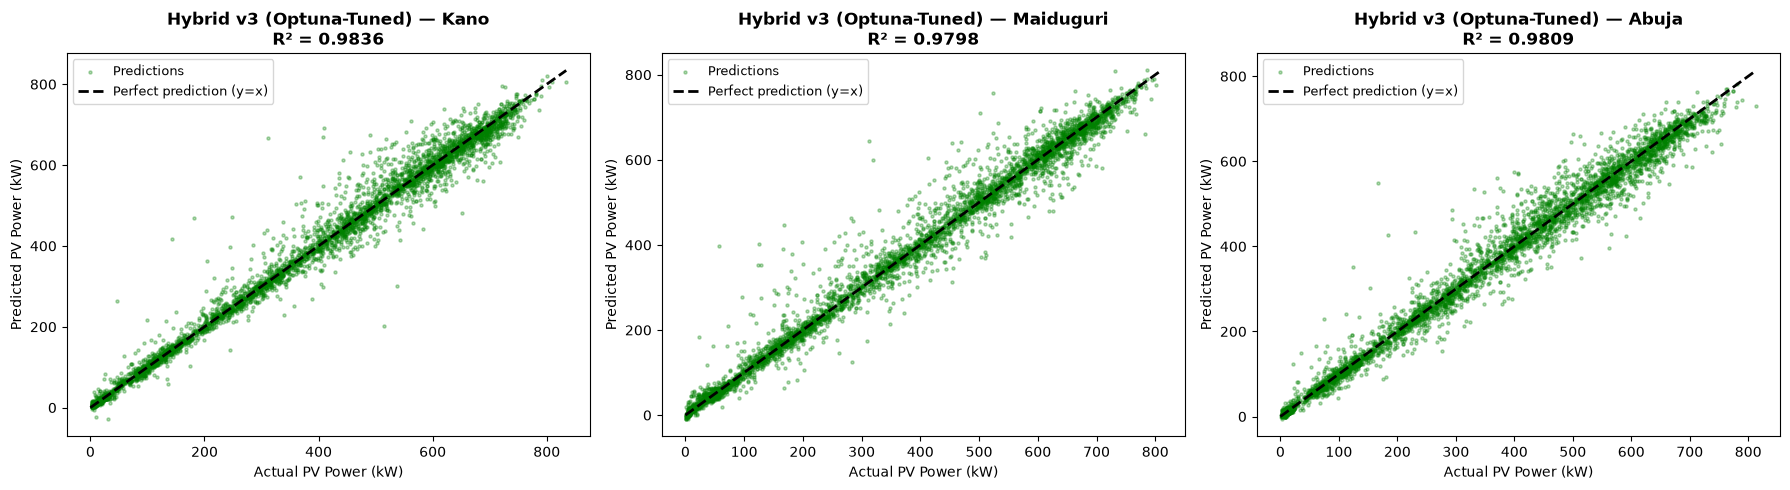

✅ Hybrid v3 (Optuna-Tuned) scatter plots saved


In [4]:
# ============================================================
# FINAL REPORT - CELL 2.5: Hybrid v3 (Optuna-Tuned) Scatter Plots
# ============================================================

from sklearn.metrics import r2_score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, city in enumerate(CITIES):
    cnn_bilstm_model = load_model(os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras'))
    cnn_pred_test = cnn_bilstm_model.predict(data[city]['X_test'], verbose=0).flatten()
    X_test_v3 = build_v3_features(data[city]['X_test'], cnn_pred_test)

    xgb_optuna_model = joblib.load(os.path.join(MODELS_DIR, f'xgb_{city}_v3_optuna.pkl'))
    residual_pred = xgb_optuna_model.predict(X_test_v3)
    hybrid_pred_norm = cnn_pred_test + residual_pred

    # Convert to real kW, daytime-only — same convention as Stage 4/5
    tgt_scaler = data[city]['tgt_scaler']
    y_pred_kw = tgt_scaler.inverse_transform(hybrid_pred_norm.reshape(-1,1)).flatten()
    y_true_kw = tgt_scaler.inverse_transform(data[city]['y_test'].reshape(-1,1)).flatten()
    mask = y_true_kw > 0

    ax = axes[idx]
    ax.scatter(y_true_kw[mask], y_pred_kw[mask], alpha=0.3, s=5, color='green', label='Predictions')

    max_val = max(y_true_kw[mask].max(), y_pred_kw[mask].max())
    ax.plot([0, max_val], [0, max_val], 'k--', linewidth=2, label='Perfect prediction (y=x)')

    r2 = r2_score(y_true_kw[mask], y_pred_kw[mask])
    ax.set_title(f'Hybrid v3 (Optuna-Tuned) — {CITY_LABELS[city]}\nR² = {r2:.4f}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual PV Power (kW)')
    ax.set_ylabel('Predicted PV Power (kW)')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'hybrid_v3_optuna_scatter_all_cities.png'), dpi=150, bbox_inches='tight')
plt.show()
print("✅ Hybrid v3 (Optuna-Tuned) scatter plots saved")

In [5]:
# ============================================================
# FINAL REPORT - CELL 3: Official 6-Model Comparison Table
# ============================================================

FINAL_MODEL_LABELS = {
    'xgb_only':         'Standalone XGBoost',
    'cnn_bilstm':       'CNN-biLSTM (Base Model)',
    'hybrid_v3_optuna': 'Hybrid v3 (Optuna-Tuned)',
}

final_report_rows = []

for city in CITIES:
    for key in ['xgb_only', 'cnn_bilstm', 'hybrid_v3_optuna']:
        m = results[city][key]
        final_report_rows.append({
            'City': CITY_LABELS[city], 'Model': FINAL_MODEL_LABELS[key],
            'RMSE': m['RMSE'], 'MAE': m['MAE'], 'MAPE': m['MAPE'], 'R2': m['R2'],
        })

    city_multi = multi_run_df[
        (multi_run_df['City'] == CITY_LABELS[city]) &
        (multi_run_df['Model'].str.contains('CNN|LSTM', regex=True)) &
        (~multi_run_df['Model'].str.contains('Hybrid|XGBoost'))
    ]
    for _, row in city_multi.iterrows():
        final_report_rows.append({
            'City': CITY_LABELS[city], 'Model': f"{row['Model']} (5-run avg)",
            'RMSE': row['RMSE_mean'], 'MAE': row['MAE_mean'],
            'MAPE': row['MAPE_mean'], 'R2': row['R2_mean'],
            'RMSE_std': row['RMSE_std'], 'MAE_std': row['MAE_std'],
            'MAPE_std': row['MAPE_std'], 'R2_std': row['R2_std'],
        })

final_report_df = pd.DataFrame(final_report_rows)

display_rows = []
for _, row in final_report_df.iterrows():
    has_std = 'RMSE_std' in row and pd.notna(row.get('RMSE_std'))
    display_rows.append({
        'City': row['City'], 'Model': row['Model'],
        'RMSE (kW)': f"{row['RMSE']:.2f} ± {row['RMSE_std']:.2f}" if has_std else f"{row['RMSE']:.2f}",
        'MAE (kW)':  f"{row['MAE']:.2f} ± {row['MAE_std']:.2f}" if has_std else f"{row['MAE']:.2f}",
        'MAPE (%)':  f"{row['MAPE']:.2f} ± {row['MAPE_std']:.2f}" if has_std else f"{row['MAPE']:.2f}",
        'R2':        f"{row['R2']:.4f} ± {row['R2_std']:.4f}" if has_std else f"{row['R2']:.4f}",
    })
display_df = pd.DataFrame(display_rows)

for city in CITIES:
    print(f"\n{'='*80}\nFINAL REPORTED COMPARISON — {CITY_LABELS[city]}\n{'='*80}")
    print(display_df[display_df['City']==CITY_LABELS[city]].drop(columns='City').to_string(index=False))

final_report_df.to_csv(os.path.join(RESULTS_DIR, 'FINAL_reported_comparison.csv'), index=False)
print(f"\n✅ Saved to: FINAL_reported_comparison.csv (6 models)")


FINAL REPORTED COMPARISON — Kano
                                 Model    RMSE (kW)     MAE (kW)     MAPE (%)              R2
                    Standalone XGBoost        29.81        17.08        11.30          0.9841
               CNN-biLSTM (Base Model)        37.16        26.00        18.79          0.9752
              Hybrid v3 (Optuna-Tuned)        30.25        16.89         9.14          0.9836
            Standalone CNN (5-run avg) 53.56 ± 9.29 40.13 ± 8.98 28.92 ± 6.47 0.9470 ± 0.0193
           Standalone LSTM (5-run avg) 32.75 ± 2.08 21.24 ± 2.41 11.52 ± 2.81 0.9807 ± 0.0024
CNN-LSTM (uni-directional) (5-run avg) 44.01 ± 4.69 31.99 ± 3.85 28.40 ± 2.53 0.9649 ± 0.0075

FINAL REPORTED COMPARISON — Maiduguri
                                 Model    RMSE (kW)     MAE (kW)     MAPE (%)              R2
                    Standalone XGBoost        33.72        19.63        17.93          0.9793
               CNN-biLSTM (Base Model)        54.17        41.49        46.29    

In [6]:
# ============================================================
# FINAL REPORT - CELL 4 (UPDATED): Composite Ranking, 4 Decimal Places
# ============================================================

for city in CITIES:
    city_df = final_report_df[final_report_df['City'] == CITY_LABELS[city]].copy()

    city_df['RMSE_rank'] = city_df['RMSE'].rank(ascending=True)
    city_df['MAE_rank']  = city_df['MAE'].rank(ascending=True)
    city_df['MAPE_rank'] = city_df['MAPE'].rank(ascending=True)
    city_df['R2_rank']   = city_df['R2'].rank(ascending=False)
    city_df['Composite_Rank'] = city_df[['RMSE_rank','MAE_rank','MAPE_rank','R2_rank']].mean(axis=1)
    city_df = city_df.sort_values('Composite_Rank')

    # Round each column individually so RMSE/MAE/MAPE stay readable
    # (2 decimals, matching kW/percentage precision used throughout
    # the project) while R2 gets its own 4-decimal precision
    display_city_df = city_df[['Model', 'RMSE', 'MAE', 'MAPE', 'R2', 'Composite_Rank']].copy()
    display_city_df['RMSE'] = display_city_df['RMSE'].round(2)
    display_city_df['MAE']  = display_city_df['MAE'].round(2)
    display_city_df['MAPE'] = display_city_df['MAPE'].round(2)
    display_city_df['R2']   = display_city_df['R2'].round(4)
    display_city_df['Composite_Rank'] = display_city_df['Composite_Rank'].round(3)

    print(f"\n{'='*70}\nFINAL COMPOSITE RANKING — {CITY_LABELS[city]}\n{'='*70}")
    print(display_city_df.to_string(index=False))


FINAL COMPOSITE RANKING — Kano
                                 Model  RMSE   MAE  MAPE     R2  Composite_Rank
                    Standalone XGBoost 29.81 17.08 11.30 0.9841             1.5
              Hybrid v3 (Optuna-Tuned) 30.25 16.89  9.14 0.9836             1.5
           Standalone LSTM (5-run avg) 32.75 21.24 11.52 0.9807             3.0
               CNN-biLSTM (Base Model) 37.16 26.00 18.79 0.9752             4.0
CNN-LSTM (uni-directional) (5-run avg) 44.01 31.99 28.40 0.9649             5.0
            Standalone CNN (5-run avg) 53.56 40.13 28.92 0.9470             6.0

FINAL COMPOSITE RANKING — Maiduguri
                                 Model  RMSE   MAE  MAPE     R2  Composite_Rank
              Hybrid v3 (Optuna-Tuned) 33.33 18.80 13.87 0.9798            1.00
                    Standalone XGBoost 33.72 19.63 17.93 0.9793            2.00
           Standalone LSTM (5-run avg) 40.34 27.16 19.93 0.9699            3.00
               CNN-biLSTM (Base Model) 54.17 41.49 

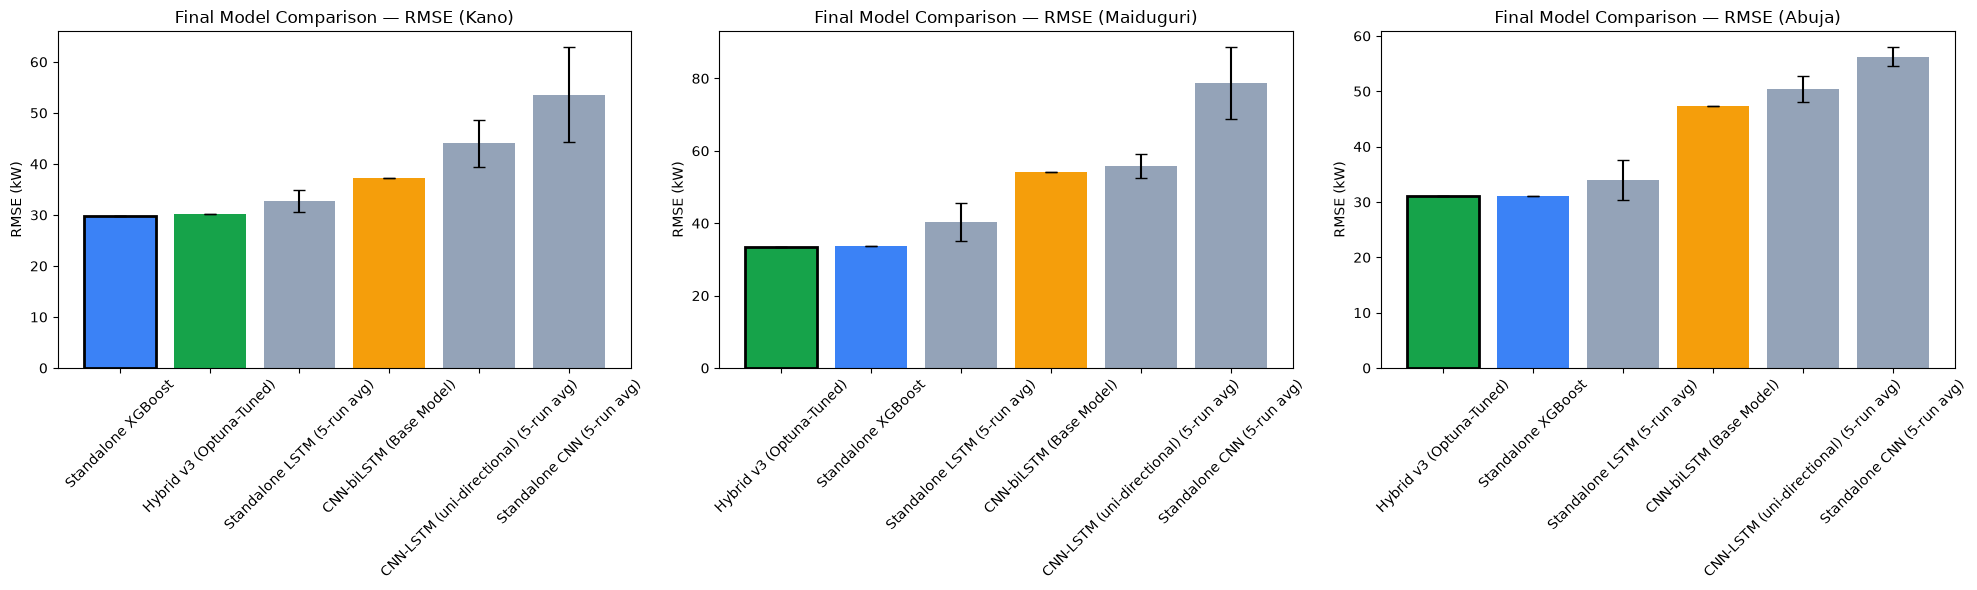

✅ Saved: FINAL_model_comparison_rmse.png


In [7]:
# ============================================================
# FINAL REPORT - CELL 5: Final RMSE Comparison Chart
# ============================================================

model_colors = {
    'Standalone XGBoost': '#3b82f6',
    'CNN-biLSTM (Base Model)': '#f59e0b',
    'Hybrid v3 (Optuna-Tuned)': '#16a34a',
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, city in enumerate(CITIES):
    city_df = final_report_df[final_report_df['City'] == CITY_LABELS[city]].copy().sort_values('RMSE')

    ax = axes[idx]
    colors = [model_colors.get(m, '#94a3b8') for m in city_df['Model']]
    error_bars = city_df['RMSE_std'].fillna(0) if 'RMSE_std' in city_df else None

    bars = ax.bar(city_df['Model'], city_df['RMSE'], color=colors, yerr=error_bars, capsize=4)
    ax.set_title(f"Final Model Comparison — RMSE ({CITY_LABELS[city]})")
    ax.set_ylabel("RMSE (kW)")
    ax.tick_params(axis='x', rotation=45)

    min_idx = city_df['RMSE'].idxmin()
    for bar, idx2 in zip(bars, city_df.index):
        if idx2 == min_idx:
            bar.set_edgecolor('black')
            bar.set_linewidth(2)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'FINAL_model_comparison_rmse.png'), dpi=300, bbox_inches="tight")
plt.show()
print("✅ Saved: FINAL_model_comparison_rmse.png")